# 04 · Tabuloc et al. transcriptomic overlap

Intersects two gene sets with the Tabuloc spinosad DEG tables (C3 vs Sus, C4 vs Sus):

1. **Triple region genes**: every gene in every triple region genome-wide (scan footprint of the triple windows, ≥ 3 of the 4 xQTL panels, any combination, peaks ≤ 500 kb apart merged; notebook 02).
2. **Outdoor × LC50-DSPR-O genes**: genes in the X-QTL scan footprint (scan position ± 50 kb, overlapping footprints merged) of windows where both the primary outdoor track (median |z|) and LC50-DSPR-O are ≥ their 95th percentile (notebook 03).

For each set and contrast: log2FC heatmap of genes significant in ≥ 1 contrast, a rank-shift test (are set genes near the top of the DEG ranking?) and a hypergeometric test (are set genes over-represented among padj < 0.05 DEGs; universe = every gene tested in that contrast; BH across the two contrasts).

The DEG tables are keyed by Dmel FBgn and can carry several *D. suzukii* orthologs per FBgn. Every test and the heatmap use one row per FBgn: the best-evidence ortholog (lowest padj, then largest |log2FC|), so a gene counts as a DEG when any of its orthologs is one.

### Inputs → outputs

| In | Out (`Final_Final_Data/`) |
|---|---|
| `Final_Data_Inputs/Tabuloc/SupplTable13_C3vsSus_DEG.xlsx` (all sheets) | `Data/04_Transcriptomic/<set>_deg_overlap.csv` |
| `Final_Data_Inputs/Tabuloc/SupplTable14_C4vsSus_DEG.xlsx` (all sheets) | `Data/04_Transcriptomic/<set>_rank_enrichment.csv` |
| `Data/02_Peaks/triple_region_genes.csv` | `Data/04_Transcriptomic/<set>_hypergeometric.csv` |
| `Data/02_Peaks/dmel_gene_coords.csv` | `Data/04_Transcriptomic/outdoor95_window_genes.csv` |
| `Data/03_Supplemental/outdoor_95th_overlap_windows.csv` | `Figures/04_Transcriptomic/<set>_deg_heatmap.png`, `<set>_hypergeometric_table.png` |

`<set>` = `triple_regions` or `outdoor95`.

## 1. Setup

In [13]:
ROOT    <- "D:/xQTL_2025_Data/Final_Window_Analysis/Analysis_jupyter_notebooks/Final_Notebooks"
IN_DIR  <- file.path(ROOT, "Final_Data_Inputs")
OUT_DIR <- file.path(ROOT, "Final_Final_Data")
D_PK    <- file.path(OUT_DIR, "Data", "02_Peaks")
D_SUP   <- file.path(OUT_DIR, "Data", "03_Supplemental")
DATA    <- file.path(OUT_DIR, "Data",    "04_Transcriptomic")
FIGS    <- file.path(OUT_DIR, "Figures", "04_Transcriptomic")
for (d in c(DATA, FIGS)) dir.create(d, recursive = TRUE, showWarnings = FALSE)
setwd(OUT_DIR)

ALPHA  <- 0.05
CHROMS <- c("2L", "2R", "3L", "3R", "X")

suppressPackageStartupMessages({
  library(tidyverse); library(readxl); library(GenomicRanges); library(IRanges)
  library(gridExtra); library(grid); library(gtable)
})

## ---- publication style shared by every figure (main + supplement) --------
SUP_RED     <- "#D2232A"; SUP_BLUE <- "#0057B8"
PANEL_ORDER <- c("z_dspr3", "z_dgrp", "z_dspr4", "z_outspino3")      # reference (LC50-DSPR-I) first
PANEL_COL   <- c("LC50-DSPR-I" = "#457b9d", "LC50-DGRP-I" = "#9d4edd", "LC90-DSPR-I" = "#2a9d8f",
                 "LC50-DSPR-O" = "#E9A23B", "Outdoor E&R" = "#6c757d")
W_FULL <- 180 / 25.4; W_HALF <- 85 / 25.4
mm     <- function(x) x / 25.4
theme_pub <- function(base = 8) {
  theme_classic(base_size = base) +
    theme(axis.line = element_line(linewidth = 0.3), axis.ticks = element_line(linewidth = 0.3),
          axis.ticks.length = unit(2, "pt"), axis.text = element_text(size = 7, colour = "black"),
          axis.title = element_text(size = 8),
          strip.background = element_blank(), strip.text = element_text(size = 7, face = "bold", hjust = 0),
          legend.title = element_text(size = 6.5, face = "bold"), legend.text = element_text(size = 6),
          legend.key.size = unit(7, "pt"), legend.margin = margin(0, 0, 0, 0),
          plot.title = element_text(size = 8, face = "bold"),
          plot.subtitle = element_text(size = 6.5, colour = "grey30"),
          plot.margin = margin(4, 6, 4, 4))
}
TAG_THEME <- theme(plot.tag = element_text(size = 10, face = "bold"))
save_pub <- function(p, name, w = W_FULL, h, dpi = 600) {
  ggsave(file.path(FIGS, paste0(name, ".png")), p, width = w, height = h, dpi = dpi, bg = "white", limitsize = FALSE)
  ggsave(file.path(FIGS, paste0(name, ".pdf")), p, width = w, height = h, device = cairo_pdf, limitsize = FALSE)
  options(repr.plot.width = w * 1.5, repr.plot.height = h * 1.5)
  invisible(p)
}

## 2. DEG tables (every sheet: Up, Down, Not Significant)

In [14]:
read_deg <- function(path) {
  bind_rows(lapply(excel_sheets(path), function(s)
    read_xlsx(path, sheet = s, guess_max = 100000) %>% mutate(sheet = s)))
}
to_fbgn <- function(df) {
  col <- names(df)[sapply(df, function(x) any(grepl("^FBgn\\d+", as.character(x))))][1]
  if (is.na(col)) stop("no FBgn-style column; names: ", paste(names(df), collapse = ", "))
  dplyr::rename(df, Fbgn = all_of(col))
}
DEG <- list(
  "C3 vs Sus" = to_fbgn(read_deg(file.path(IN_DIR, "Tabuloc/SupplTable13_C3vsSus_DEG.xlsx"))),
  "C4 vs Sus" = to_fbgn(read_deg(file.path(IN_DIR, "Tabuloc/SupplTable14_C4vsSus_DEG.xlsx"))))
for (nm in names(DEG)) { cat(nm, ": ", nrow(DEG[[nm]]), " rows\n", sep = ""); print(count(DEG[[nm]], sheet)) }

## one row per FBgn: best-evidence ortholog (lowest padj, then largest |log2FC|); NA padj sorts last
best_per_gene <- function(deg) {
  deg %>%
    transmute(Fbgn = as.character(Fbgn),
              padj = suppressWarnings(as.numeric(padj)),
              log2FC = suppressWarnings(as.numeric(log2FoldChange))) %>%
    filter(!is.na(Fbgn)) %>%
    arrange(padj, desc(abs(log2FC))) %>%
    distinct(Fbgn, .keep_all = TRUE)
}
DEG1 <- lapply(DEG, best_per_gene)
sapply(DEG1, function(d) c(genes_tested = nrow(d), sig = sum(d$padj < ALPHA, na.rm = TRUE)))

C3 vs Sus: 12612 rows
# A tibble: 3 × 2
  sheet               n
  <chr>           <int>
1 Downregulated     496
2 Not Significant 11756
3 Upregulated       360
C4 vs Sus: 12579 rows
# A tibble: 3 × 2
  sheet               n
  <chr>           <int>
1 Downregulated    2312
2 Not Significant  8166
3 Upregulated      2101


,C3 vs Sus,C4 vs Sus
genes_tested,8067,8032
sig,563,3377


## 3. Gene sets

In [16]:
gene_coords <- as_tibble(read.csv(file.path(D_PK, "dmel_gene_coords.csv"), stringsAsFactors = FALSE))
lab_gene <- function(name, id) ifelse(is.na(name) | name == "", id, name)

## set 1: every gene in every triple region (scan footprint; any 3 of 4 panels)
set_triple <- read.csv(file.path(D_PK, "triple_region_genes.csv"), stringsAsFactors = FALSE) %>%
  transmute(Fbgn = ensembl_gene_id, gene = lab_gene(gene_name, ensembl_gene_id), group = region) %>%
  distinct(Fbgn, .keep_all = TRUE)

## set 2: genes in outdoor x LC50-DSPR-O joint 95th windows
win95 <- read.csv(file.path(D_SUP, "outdoor_95th_overlap_windows.csv"), stringsAsFactors = FALSE) %>%
  mutate(chr = as.character(chr))
if (!all(c("fp_start", "fp_end") %in% names(win95)))      # older 03 output: build the scan footprint here
  win95 <- win95 %>% mutate(fp_start = win_start + 25000 - 50000, fp_end = win_end - 25000 + 50000)
## genes from the X-QTL scan footprint of each joint window; overlapping footprints merged first
fp95 <- reduce(GRanges(win95$chr, IRanges(win95$fp_start, win95$fp_end - 1)))
fp95 <- data.frame(chr = as.character(seqnames(fp95)), fp_start = start(fp95), fp_end = end(fp95) + 1)
h <- findOverlaps(GRanges(fp95$chr, IRanges(fp95$fp_start, fp95$fp_end - 1)),
                  GRanges(gene_coords$gene_chr, IRanges(gene_coords$gene_start, gene_coords$gene_end)))
outdoor95_genes <- bind_cols(fp95[queryHits(h), c("chr", "fp_start", "fp_end")], gene_coords[subjectHits(h), ])
write.csv(outdoor95_genes, file.path(DATA, "outdoor95_window_genes.csv"), row.names = FALSE)
set_out95 <- outdoor95_genes %>%
  transmute(Fbgn = ensembl_gene_id, gene = lab_gene(gene_name, ensembl_gene_id), group = "Outdoor x LC50-DSPR-O") %>%
  distinct(Fbgn, .keep_all = TRUE)

cat(sprintf("triple-region genes: %d (%d regions: %s) | outdoor95 genes: %d (%d windows -> %d merged footprints)\n",
            nrow(set_triple), n_distinct(set_triple$group), paste(unique(set_triple$group), collapse = ", "),
            nrow(set_out95), nrow(win95), nrow(fp95)))

triple-region genes: 175 (4 regions: 2L_Consensus, 2R_1, 3L_1, 3L_2) | outdoor95 genes: 130 (8 windows -> 5 merged footprints)


## 4. Overlap, rank enrichment, hypergeometric: one function for both sets

In [17]:
star <- function(p) ifelse(p < 0.001, "***", ifelse(p < 0.01, "**", ifelse(p < 0.05, "*", "ns")))
save_table_png <- function(disp, title, file, foot = NULL) {
  th <- ttheme_minimal(
    core    = list(fg_params = list(fontsize = 7), bg_params = list(fill = c("grey95", "white"), col = NA)),
    colhead = list(fg_params = list(fontface = "bold", fontsize = 7, col = "white"),
                   bg_params = list(fill = SUP_BLUE, col = NA)))
  tg  <- tableGrob(disp, rows = NULL, theme = th)
  tit <- textGrob(title, gp = gpar(fontface = "bold", fontsize = 9))
  tab <- gtable_add_rows(tg, heights = grobHeight(tit) + unit(6, "mm"), pos = 0)
  tab <- gtable_add_grob(tab, tit, t = 1, l = 1, r = ncol(tg), clip = "off")
  if (!is.null(foot)) {
    ft  <- textGrob(foot, x = 0.01, hjust = 0, gp = gpar(fontsize = 6, col = "grey35"))
    tab <- gtable_add_rows(tab, heights = grobHeight(ft) + unit(4, "mm"), pos = -1)
    tab <- gtable_add_grob(tab, ft, t = nrow(tab), l = 1, r = ncol(tab), clip = "off")
  }
  pdf(NULL)
  gw <- max(convertWidth(sum(tab$widths), "in", valueOnly = TRUE), convertWidth(grobWidth(tit), "in", valueOnly = TRUE))
  gh <- convertHeight(sum(tab$heights), "in", valueOnly = TRUE)
  dev.off()
  png(file, width = gw + 0.8, height = gh + 0.8, units = "in", res = 300, bg = "white")
  grid.newpage(); pushViewport(viewport(width = unit(gw, "in"), height = unit(gh, "in")))
  grid.draw(tab); popViewport(); dev.off()
  grid.newpage(); grid.draw(tab)
}

run_set <- function(gs, tag, title) {
  ## ---- per-contrast overlap table (best ortholog per gene) ----------------
  ov <- bind_rows(lapply(names(DEG1), function(ct)
    gs %>% inner_join(DEG1[[ct]], by = "Fbgn") %>% mutate(contrast = ct)))
  write.csv(ov, file.path(DATA, paste0(tag, "_deg_overlap.csv")), row.names = FALSE)
  cat(sprintf("[%s] set genes: %d | tested in C3: %d (%d sig) | tested in C4: %d (%d sig)\n", tag, nrow(gs),
              sum(ov$contrast == "C3 vs Sus"), sum(ov$contrast == "C3 vs Sus" & ov$padj < ALPHA, na.rm = TRUE),
              sum(ov$contrast == "C4 vs Sus"), sum(ov$contrast == "C4 vs Sus" & ov$padj < ALPHA, na.rm = TRUE)))

  ## ---- rank shift: set genes vs the rest of the DEG ranking ---------------
  rank_res <- bind_rows(lapply(names(DEG1), function(ct) {
    d <- DEG1[[ct]] %>% mutate(rank = row_number())          # already sorted by padj, then |log2FC|
    is_set <- d$Fbgn %in% gs$Fbgn; N <- nrow(d)
    pct <- (d$rank[is_set] - 0.5) / N
    tibble(contrast = ct, N_tested = N, n_set = sum(is_set),
           median_pctile = median(pct), mean_pctile = mean(pct),           # < 0.5 = shifted toward the top
           wilcox_p = wilcox.test(d$rank[is_set], d$rank[!is_set], alternative = "less")$p.value,
           set_not_tested = nrow(gs) - sum(is_set))
  }))
  write.csv(rank_res, file.path(DATA, paste0(tag, "_rank_enrichment.csv")), row.names = FALSE)
  print(rank_res)

  ## ---- hypergeometric: set genes among padj < ALPHA DEGs ------------------
  hyp <- bind_rows(lapply(names(DEG1), function(ct) {
    d <- DEG1[[ct]]
    universe <- d$Fbgn; sig <- d$Fbgn[!is.na(d$padj) & d$padj < ALPHA]
    set_u <- intersect(gs$Fbgn, universe); hits <- intersect(set_u, sig)
    N <- length(universe); K <- length(sig); n <- length(set_u); k <- length(hits)
    tibble(contrast = ct, N_universe = N, K_sigDEG = K, n_setTested = n, k_overlap = k,
           expected = n * K / N, fold_enrichment = k / (n * K / N),
           p_hyper = phyper(k - 1, K, N - K, n, lower.tail = FALSE),
           hit_genes = paste(gs$gene[match(hits, gs$Fbgn)], collapse = ", "))
  })) %>% mutate(p_BH = p.adjust(p_hyper, "BH"))
  write.csv(hyp, file.path(DATA, paste0(tag, "_hypergeometric.csv")), row.names = FALSE)
  print(dplyr::select(hyp, -hit_genes))

  disp <- hyp %>% transmute(Contrast = contrast, `Genes tested` = N_universe, `Sig. DEGs` = K_sigDEG,
                            `Set genes` = n_setTested, Overlap = k_overlap, Expected = round(expected, 2),
                            `Fold enrich.` = round(fold_enrichment, 2),
                            `p (hyper)` = format(p_hyper, scientific = TRUE, digits = 2),
                            `p (BH)` = format(p_BH, scientific = TRUE, digits = 2), Sig. = star(p_BH))
  foot <- paste0(paste(sprintf("Overlap genes, %s: %s", hyp$contrast, ifelse(hyp$hit_genes == "", "none", hyp$hit_genes)),
                       collapse = "\n"),
                 "\nFold enrichment = overlap / expected under the hypergeometric null; BH across 2 contrasts.")
  save_table_png(disp, paste0(title, ": hypergeometric enrichment of DEGs"),
                 file.path(FIGS, paste0(tag, "_hypergeometric_table.png")), foot = foot)

  ## ---- heatmap: genes significant in >= 1 contrast ------------------------
  sig_ids <- unique(ov$Fbgn[!is.na(ov$padj) & ov$padj < ALPHA])
  if (!length(sig_ids)) { message("[", tag, "] no set gene is a DEG in either contrast: heatmap skipped"); return(invisible(hyp)) }
  hm_df <- ov %>% filter(Fbgn %in% sig_ids) %>%
    mutate(sig = ifelse(!is.na(padj) & padj < ALPHA, "*", ""))
  ord <- hm_df %>% group_by(gene, group) %>% summarise(o = max(abs(log2FC), na.rm = TRUE), .groups = "drop") %>%
    arrange(group, o)
  hm_df <- hm_df %>% mutate(gene = factor(gene, levels = unique(ord$gene)))
  lim <- max(abs(hm_df$log2FC), na.rm = TRUE)
  hm <- ggplot(hm_df, aes(contrast, gene, fill = log2FC)) +
    geom_tile(colour = "white", linewidth = 0.4) +
    geom_text(aes(label = sig), colour = "grey15", size = 2.6, vjust = 0.78) +
    scale_fill_gradient2(low = SUP_BLUE, mid = "grey96", high = SUP_RED, midpoint = 0,
                         limits = c(-lim, lim), na.value = "grey90", name = expression(log[2]*"FC"),
                         guide = guide_colourbar(barwidth = unit(2, "mm"), barheight = unit(18, "mm"))) +
    scale_x_discrete(position = "top") +
    labs(x = NULL, y = NULL) +
    theme_pub() +
    theme(axis.line = element_blank(), axis.ticks = element_blank(),
          axis.text.y = element_text(face = "italic", size = 6.5), axis.text.x = element_text(size = 7))
  if (n_distinct(hm_df$group) > 1)
    hm <- hm + facet_grid(group ~ ., scales = "free_y", space = "free_y", switch = "y") +
      theme(strip.placement = "outside", strip.text.y.left = element_text(angle = 0, face = "bold", size = 6.5))
  save_pub(hm, paste0(tag, "_deg_heatmap"), w = mm(110), h = mm(max(40, 4.2 * nlevels(hm_df$gene) + 20)))
  print(hm)
  invisible(hyp)
}

## 5. Triple region genes (any 3 of 4 panels)

Data: `triple_regions_deg_overlap.csv`, `triple_regions_rank_enrichment.csv`, `triple_regions_hypergeometric.csv`. Figures: `triple_regions_deg_heatmap.png`, `triple_regions_hypergeometric_table.png`.

[triple_regions] set genes: 175 | tested in C3: 76 (6 sig) | tested in C4: 76 (29 sig)
# A tibble: 2 × 7
  contrast  N_tested n_set median_pctile mean_pctile wilcox_p set_not_tested
  <chr>        <int> <int>         <dbl>       <dbl>    <dbl>          <int>
1 C3 vs Sus     8067    76         0.390       0.451   0.0670             99
2 C4 vs Sus     8032    76         0.552       0.510   0.619              99
# A tibble: 2 × 9
  contrast  N_universe K_sigDEG n_setTested k_overlap expected fold_enrichment
  <chr>          <int>    <int>       <int>     <int>    <dbl>           <dbl>
1 C3 vs Sus       8067      563          76         6     5.30           1.13 
2 C4 vs Sus       8032     3377          76        29    32.0            0.908
# ℹ 2 more variables: p_hyper <dbl>, p_BH <dbl>


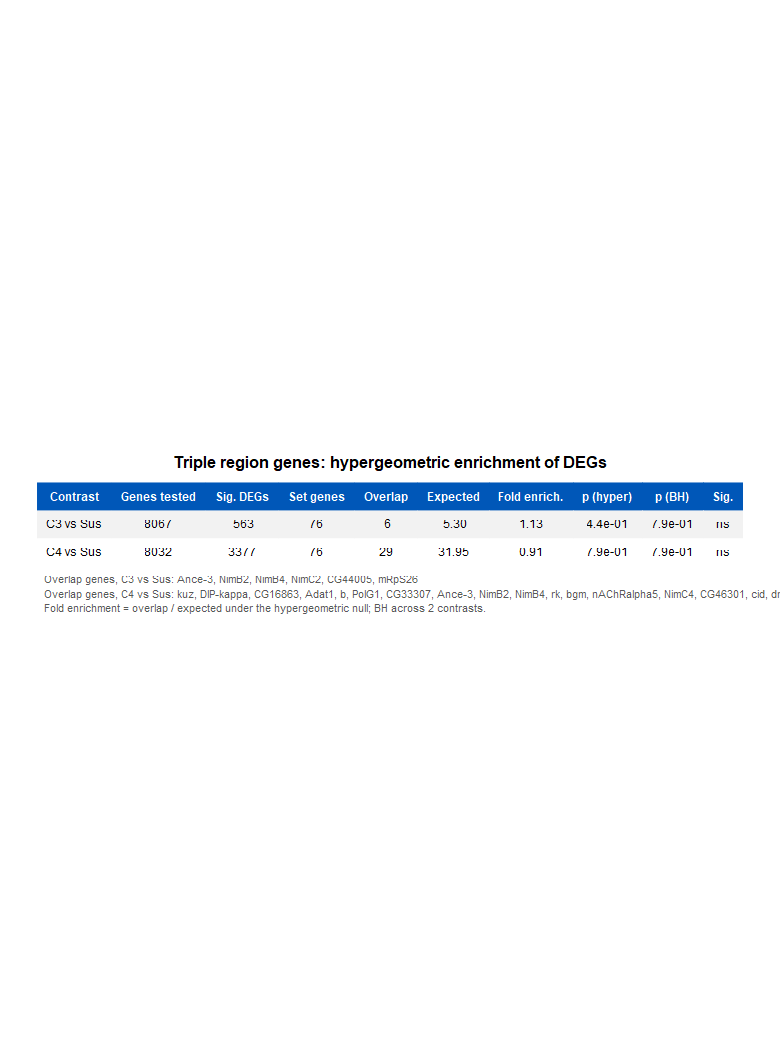

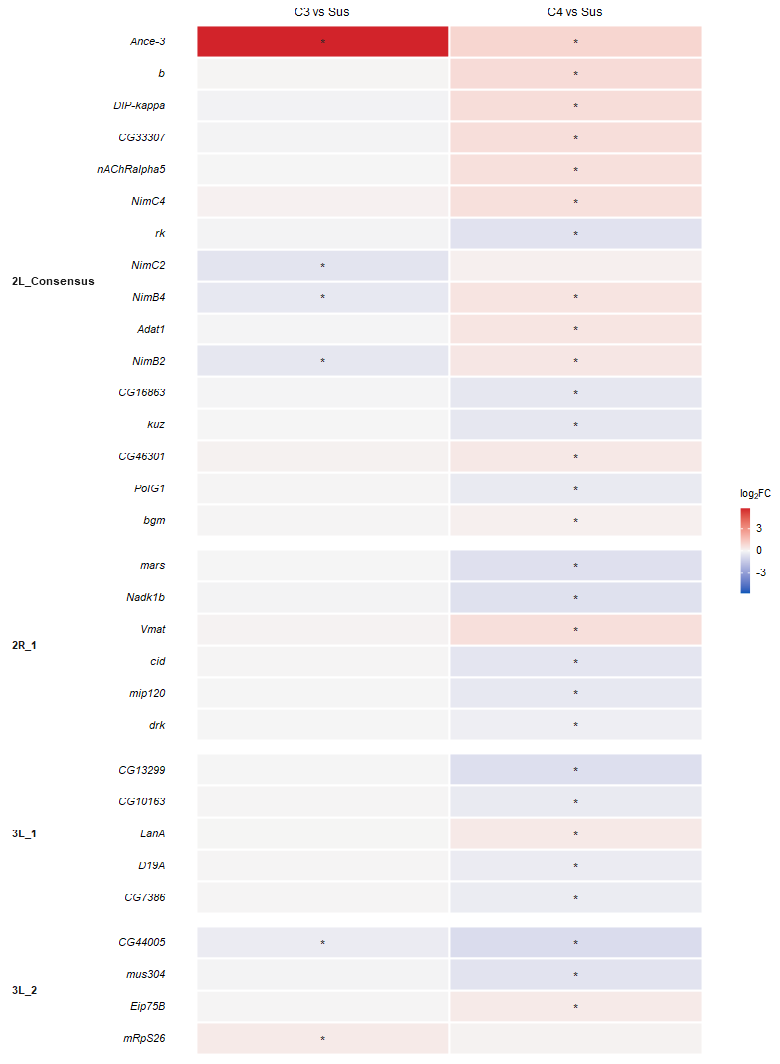

In [18]:
res_triple <- run_set(set_triple, "triple_regions", "Triple region genes")

## 6. Outdoor × LC50-DSPR-O joint 95th-percentile window genes (scan footprint)

Data: `outdoor95_deg_overlap.csv`, `outdoor95_rank_enrichment.csv`, `outdoor95_hypergeometric.csv`. Figures: `outdoor95_deg_heatmap.png`, `outdoor95_hypergeometric_table.png`.

[outdoor95] set genes: 130 | tested in C3: 62 (9 sig) | tested in C4: 64 (21 sig)
# A tibble: 2 × 7
  contrast  N_tested n_set median_pctile mean_pctile wilcox_p set_not_tested
  <chr>        <int> <int>         <dbl>       <dbl>    <dbl>          <int>
1 C3 vs Sus     8067    62         0.479       0.435   0.0366             68
2 C4 vs Sus     8032    64         0.629       0.567   0.969              66
# A tibble: 2 × 9
  contrast  N_universe K_sigDEG n_setTested k_overlap expected fold_enrichment
  <chr>          <int>    <int>       <int>     <int>    <dbl>           <dbl>
1 C3 vs Sus       8067      563          62         9     4.33           2.08 
2 C4 vs Sus       8032     3377          64        21    26.9            0.780
# ℹ 2 more variables: p_hyper <dbl>, p_BH <dbl>


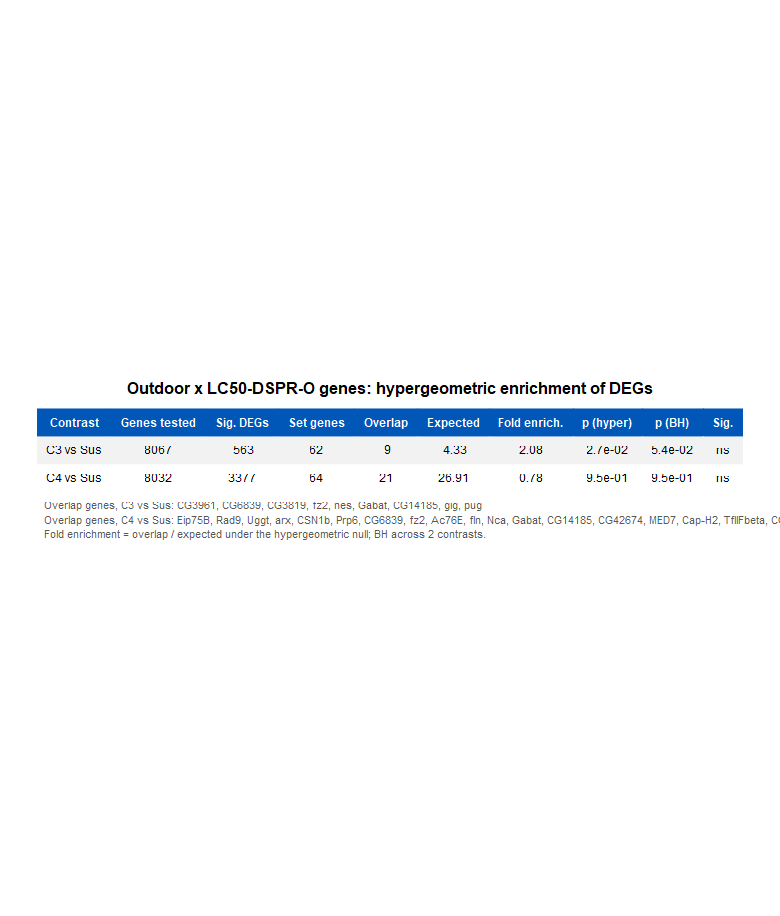

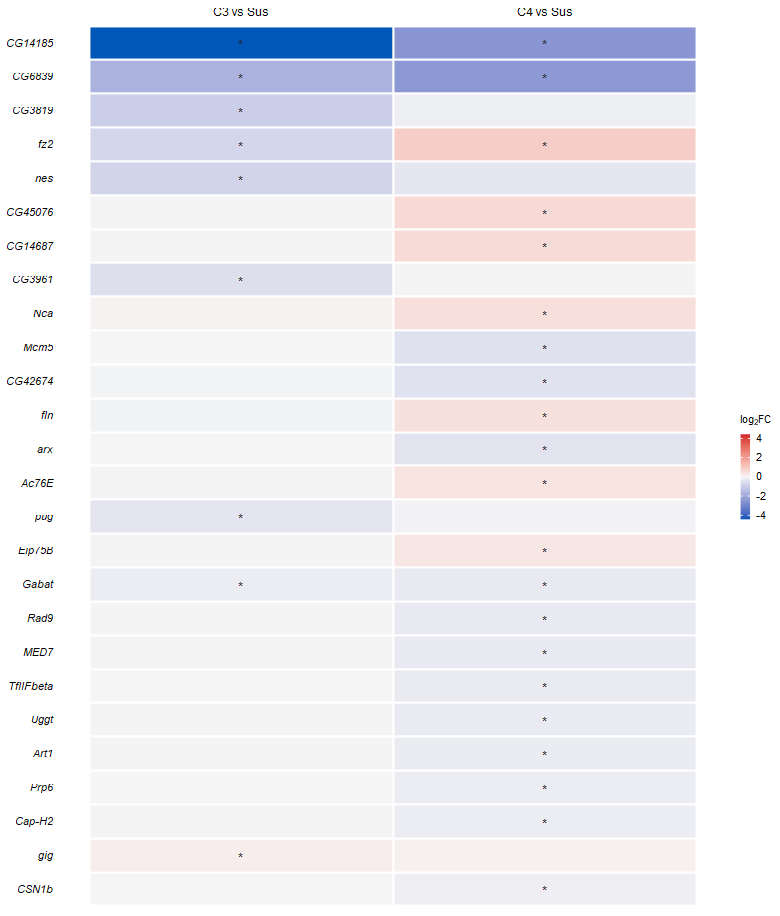

In [19]:
res_out95 <- run_set(set_out95, "outdoor95", "Outdoor x LC50-DSPR-O genes")